# Mini Project: Dry Bean Type Classification

## 1. Import and Load the Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.svm import SVC
from scipy.stats import randint
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.preprocessing import StandardScaler, PowerTransformer

import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              BaggingClassifier, HistGradientBoostingClassifier, VotingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
import joblib


In [2]:
df = pd.read_csv('Beans_Dataset.csv')
target = "Class"
features = [c for c in df.columns if c != target]
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
print(df.shape)
df.info()

(13611, 17)
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(

In [4]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


## 2. Exploratory Data Analysis (EDA)

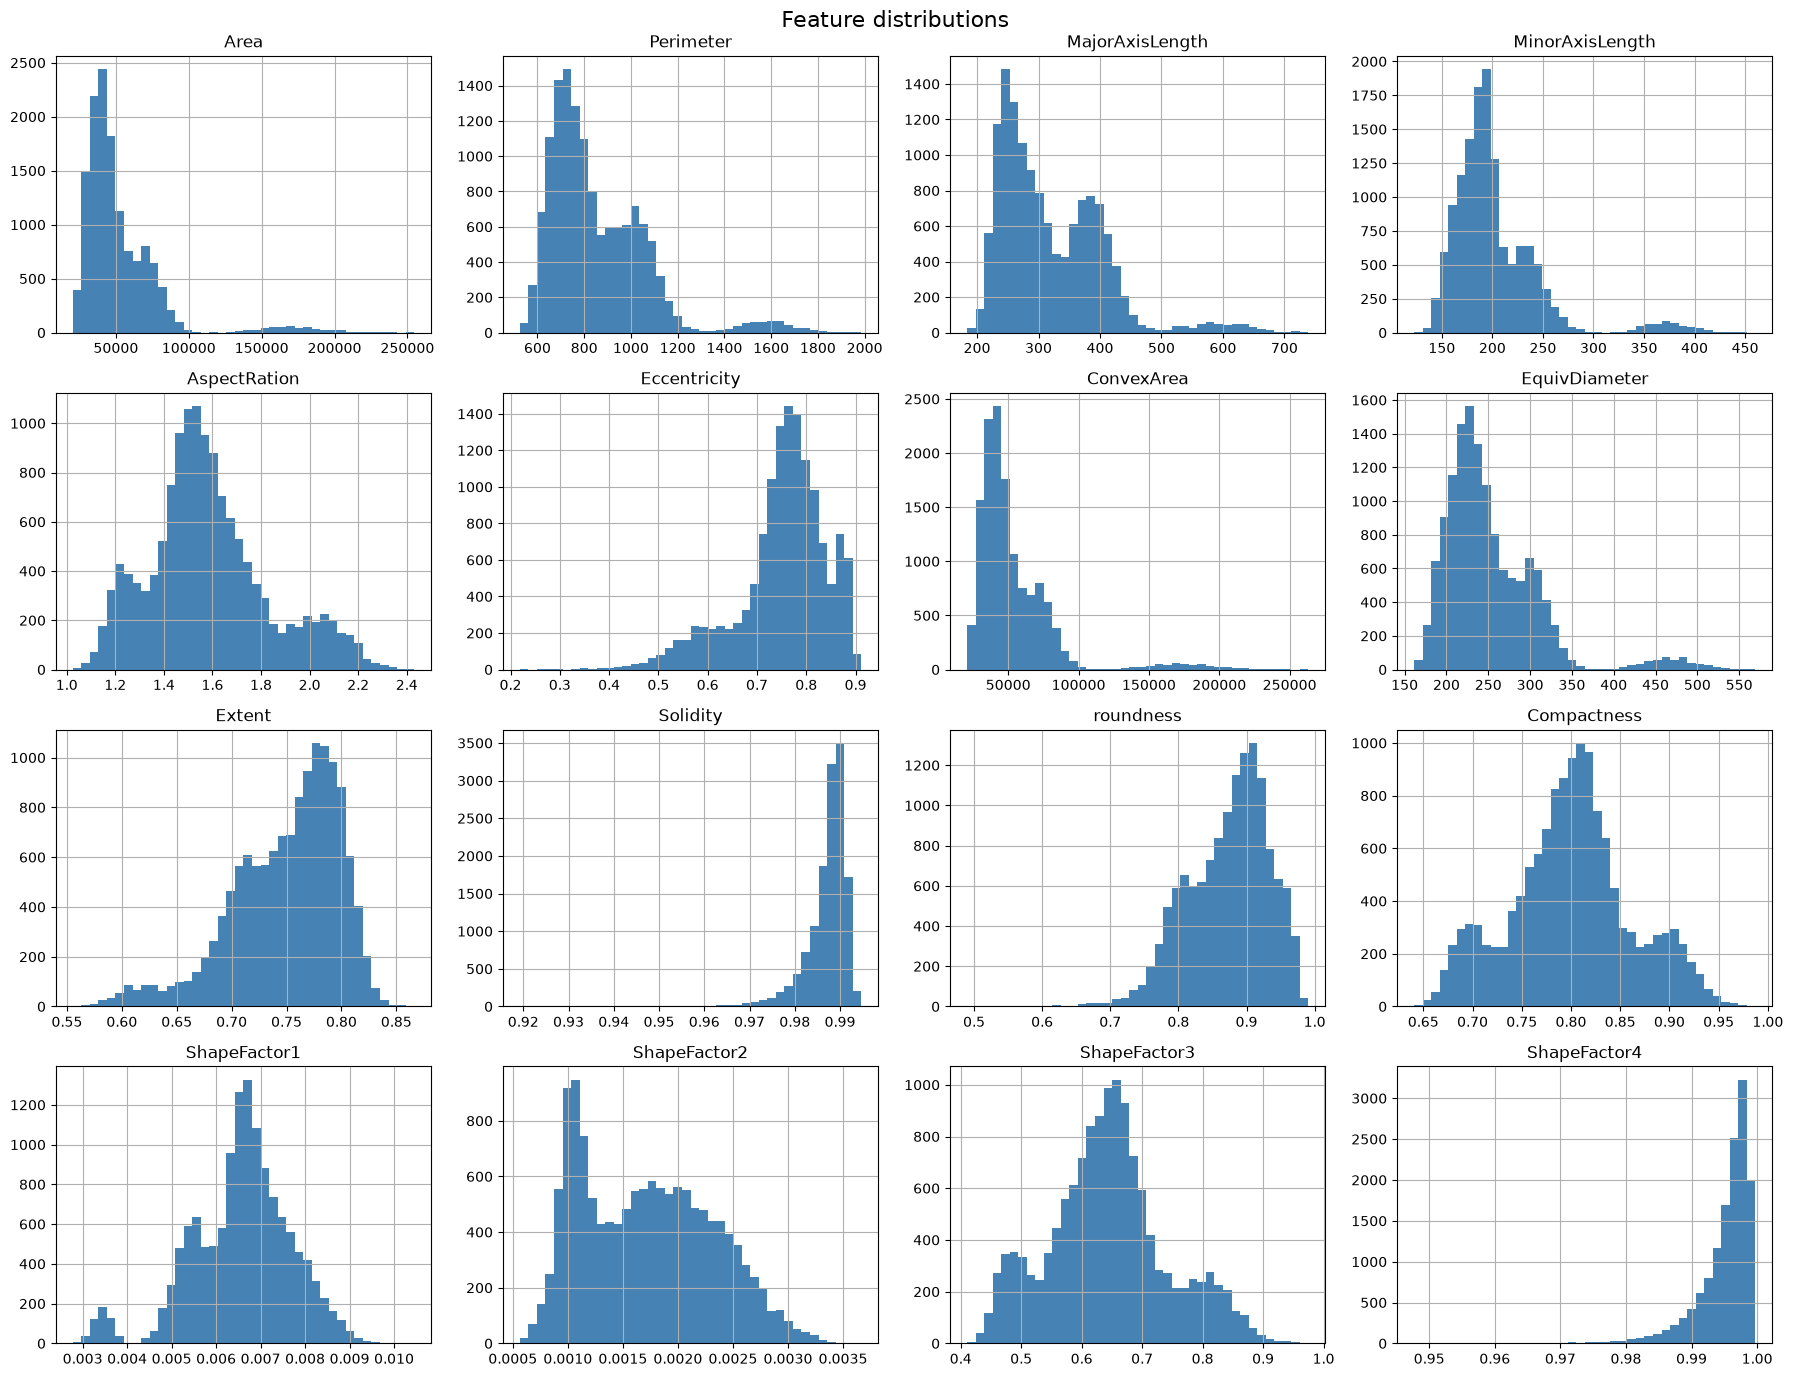

In [5]:
df[features].hist(bins=40, figsize=(18, 14), color="steelblue")
plt.suptitle("Feature distributions", fontsize=16)
plt.tight_layout()
plt.show()


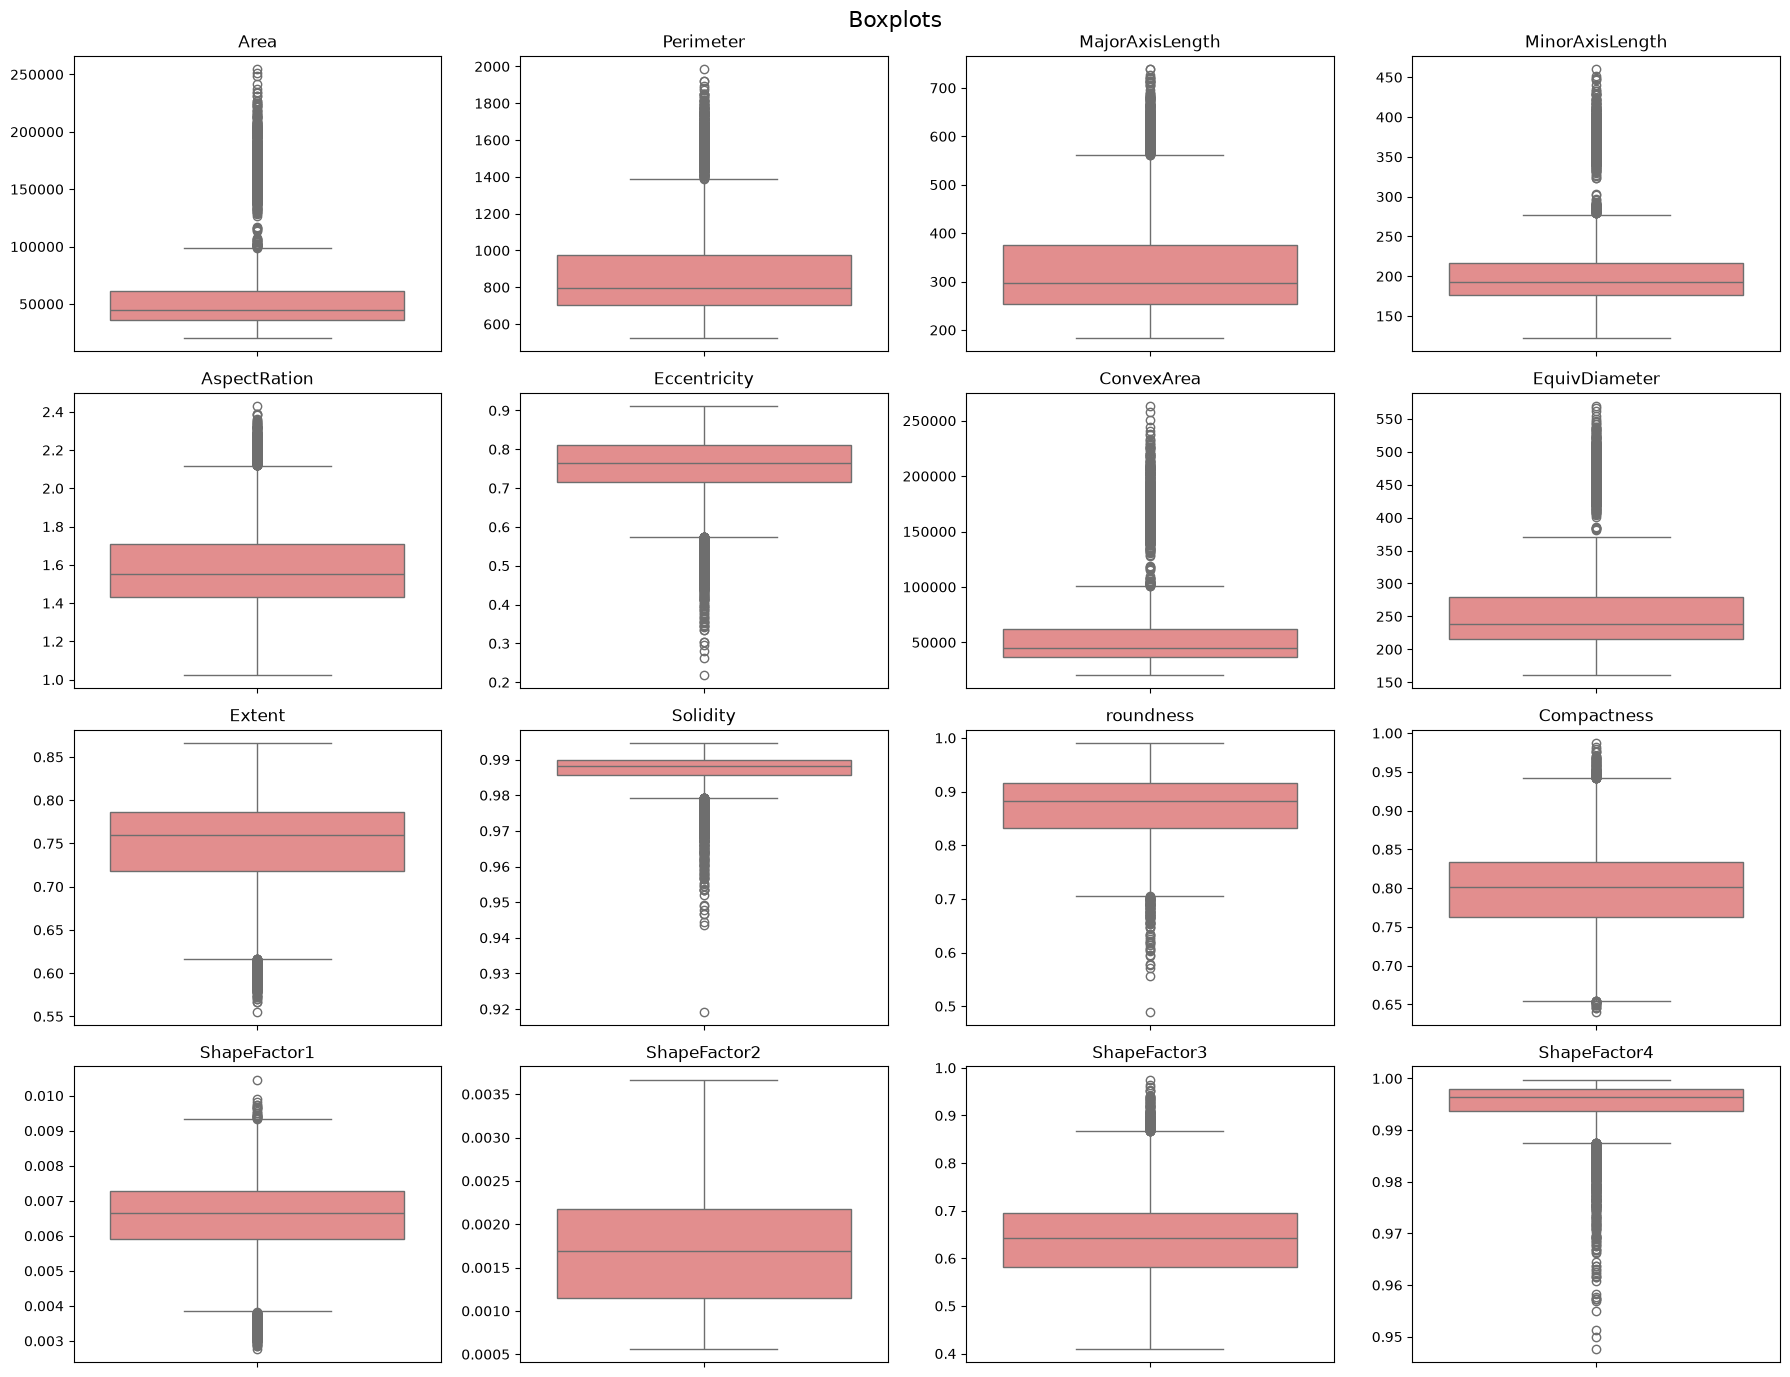

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Boxplots", fontsize=16)
plt.tight_layout()
plt.show()


          count  percent
Class                   
DERMASON   3546    26.05
SIRA       2636    19.37
SEKER      2027    14.89
HOROZ      1928    14.17
CALI       1630    11.98
BARBUNYA   1322     9.71
BOMBAY      522     3.84
Imbalance ratio (max/min): 6.79


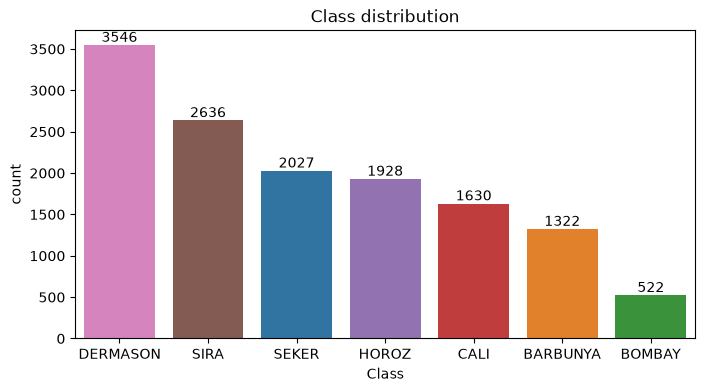

In [7]:
counts = df[target].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")
 
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x=target, order=counts.index, hue=target, legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Class distribution")
plt.show()


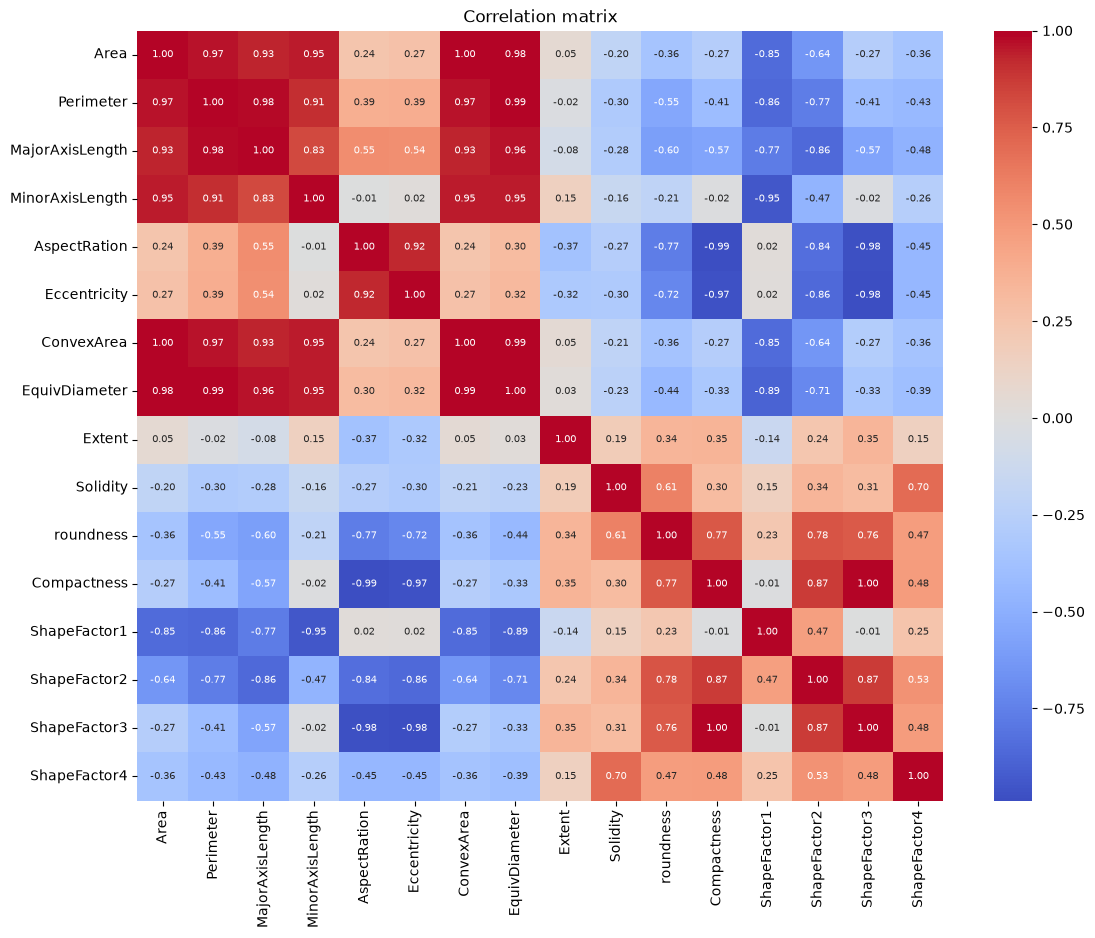

In [8]:
corr = df[features].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix")
plt.show()


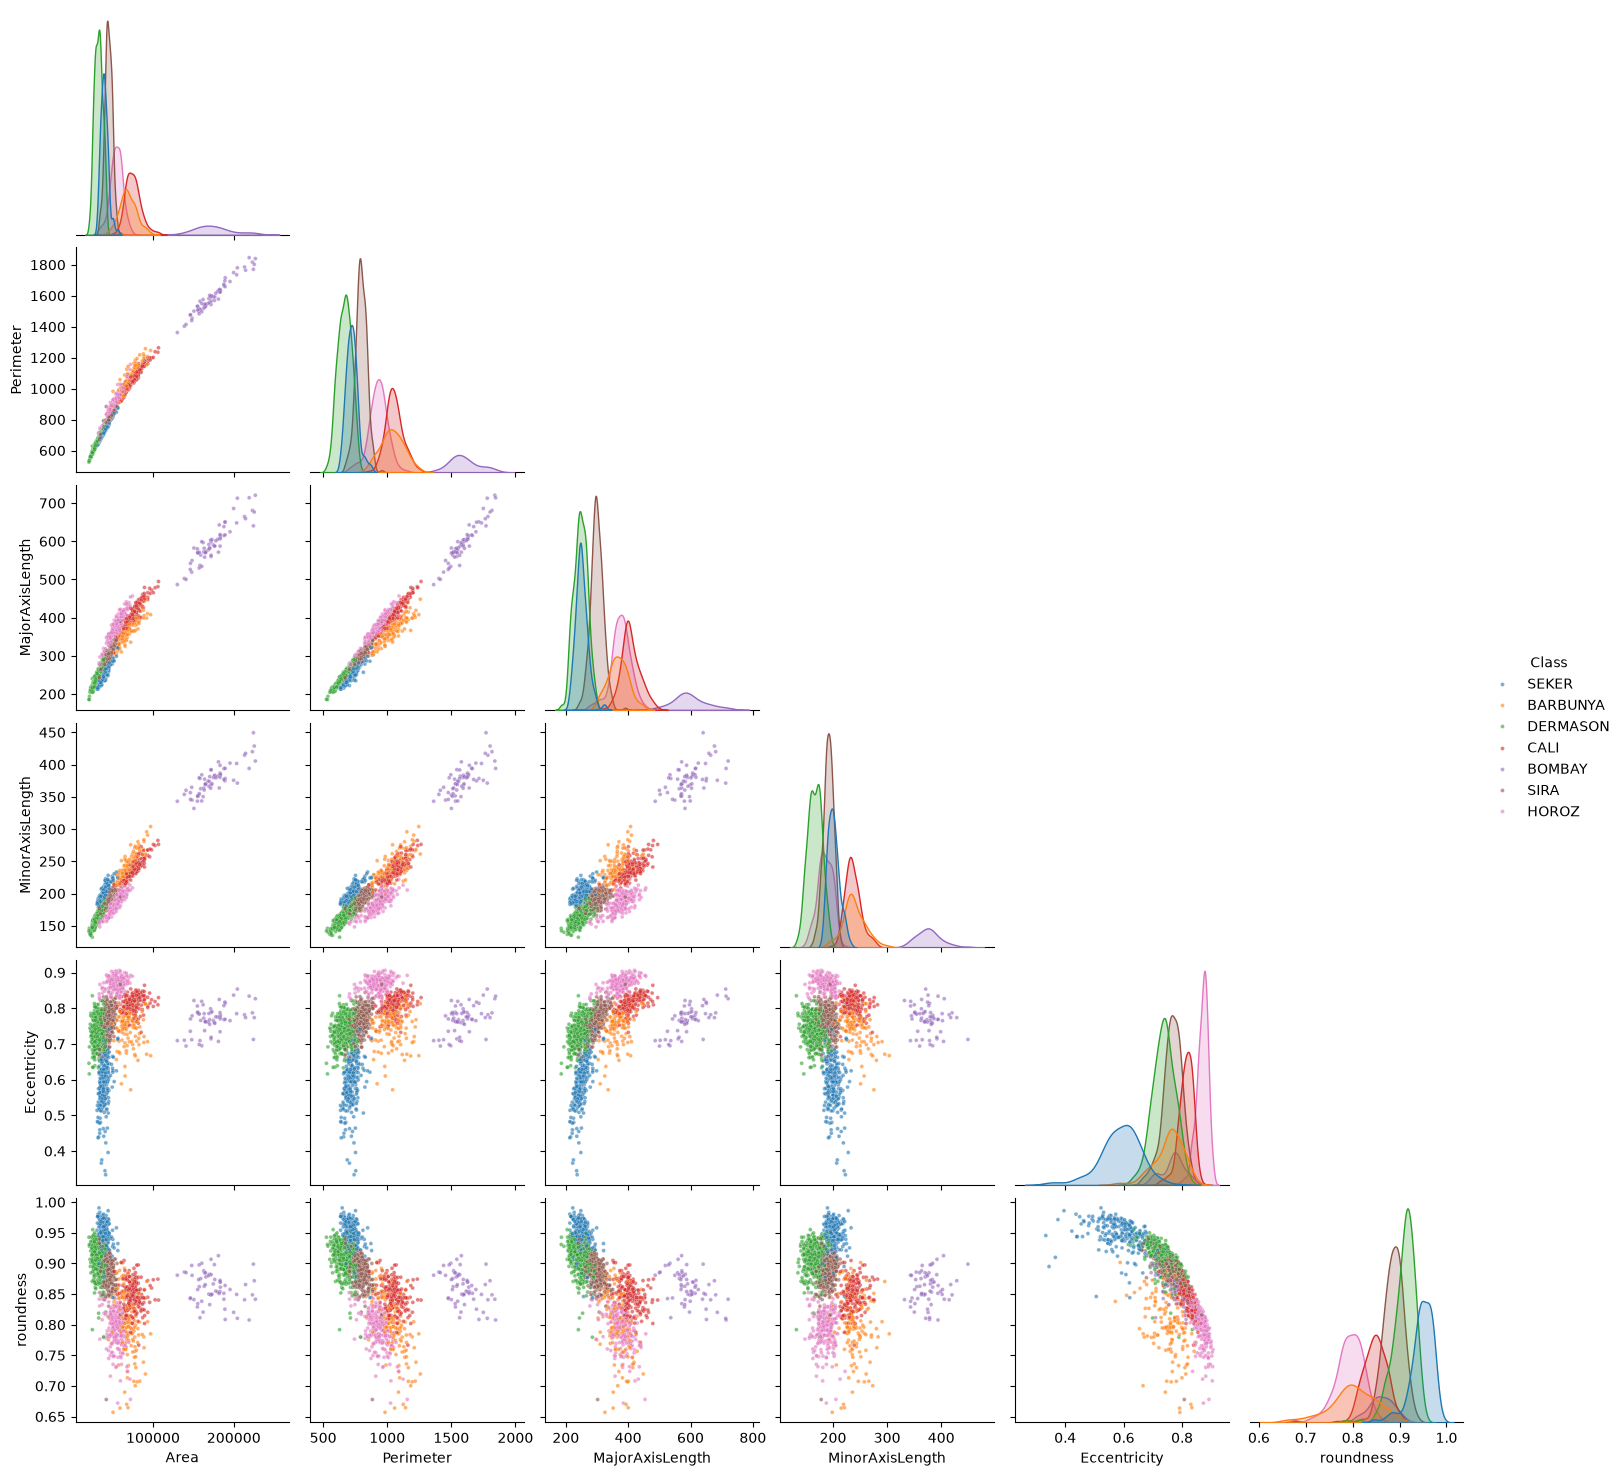

In [9]:
cols = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "Eccentricity", "roundness"]
sns.pairplot(df.sample(1500, random_state=42), vars=cols, hue=target,
             corner=True, plot_kws={"s": 8, "alpha": 0.6})
plt.show()


In [10]:
skew = df[features].skew().abs().sort_values(ascending=False)
high = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high = high[high.abs() > 0.9]
print("\nKEY FINDINGS")
print(f"- No missing values; {df.duplicated().sum()} duplicate rows.")
print(f"- Imbalance: '{counts.idxmax()}' has {counts.max()} rows, '{counts.idxmin()}' only {counts.min()}.")
print("- Most skewed:", ", ".join(skew.head(4).index))
print(f"- {len(high)} feature pairs with |corr| > 0.9 (multicollinearity).")
print("- Features are on very different scales -> scaling needed for LR / KNN / SVM.")



KEY FINDINGS
- No missing values; 68 duplicate rows.
- Imbalance: 'DERMASON' has 3546 rows, 'BOMBAY' only 522.
- Most skewed: Area, ConvexArea, ShapeFactor4, Solidity
- 21 feature pairs with |corr| > 0.9 (multicollinearity).
- Features are on very different scales -> scaling needed for LR / KNN / SVM.


## 3. Missing Values & Outlier Treatment

In [11]:
print("Missing values per column:")
print(df.isna().sum())
print("\nTotal missing:", df.isna().sum().sum())


Missing values per column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Total missing: 0


In [12]:
print (" No Missing Values in the dataset.")


 No Missing Values in the dataset.


In [13]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


In [14]:
z = (df[features] - df[features].mean()) / df[features].std()
 
summary = pd.DataFrame({
    "IQR_outliers": [((df[c] < iqr_bounds(df[c])[0]) | (df[c] > iqr_bounds(df[c])[1])).sum() for c in features],
    "Zscore_outliers": (z.abs() > 3).sum().values,
}, index=features)
summary["IQR_%"] = (summary["IQR_outliers"] / len(df) * 100).round(2)
summary["Zscore_%"] = (summary["Zscore_outliers"] / len(df) * 100).round(2)
print("\nOutlier counts per feature:")
print(summary.sort_values("IQR_outliers", ascending=False))
 
rows_iqr = pd.concat([(df[c] < iqr_bounds(df[c])[0]) | (df[c] > iqr_bounds(df[c])[1]) for c in features], axis=1).any(axis=1)
rows_z = (z.abs() > 3).any(axis=1)
print(f"\nRows with at least one outlier -> IQR: {rows_iqr.sum()} ({rows_iqr.mean()*100:.1f}%), "
      f"Z-score: {rows_z.sum()} ({rows_z.mean()*100:.1f}%)")



Outlier counts per feature:
                 IQR_outliers  Zscore_outliers  IQR_%  Zscore_%
Eccentricity              843              125   6.19      0.92
Solidity                  778              238   5.72      1.75
ShapeFactor4              767              242   5.64      1.78
MinorAxisLength           569              508   4.18      3.73
Area                      551              483   4.05      3.55
ConvexArea                550              483   4.04      3.55
ShapeFactor1              533               59   3.92      0.43
EquivDiameter             526              465   3.86      3.42
Perimeter                 500              404   3.67      2.97
AspectRation              473               15   3.48      0.11
MajorAxisLength           379              316   2.78      2.32
Extent                    275              135   2.02      0.99
ShapeFactor3              195                8   1.43      0.06
Compactness               109                1   0.80      0.01
roundness  

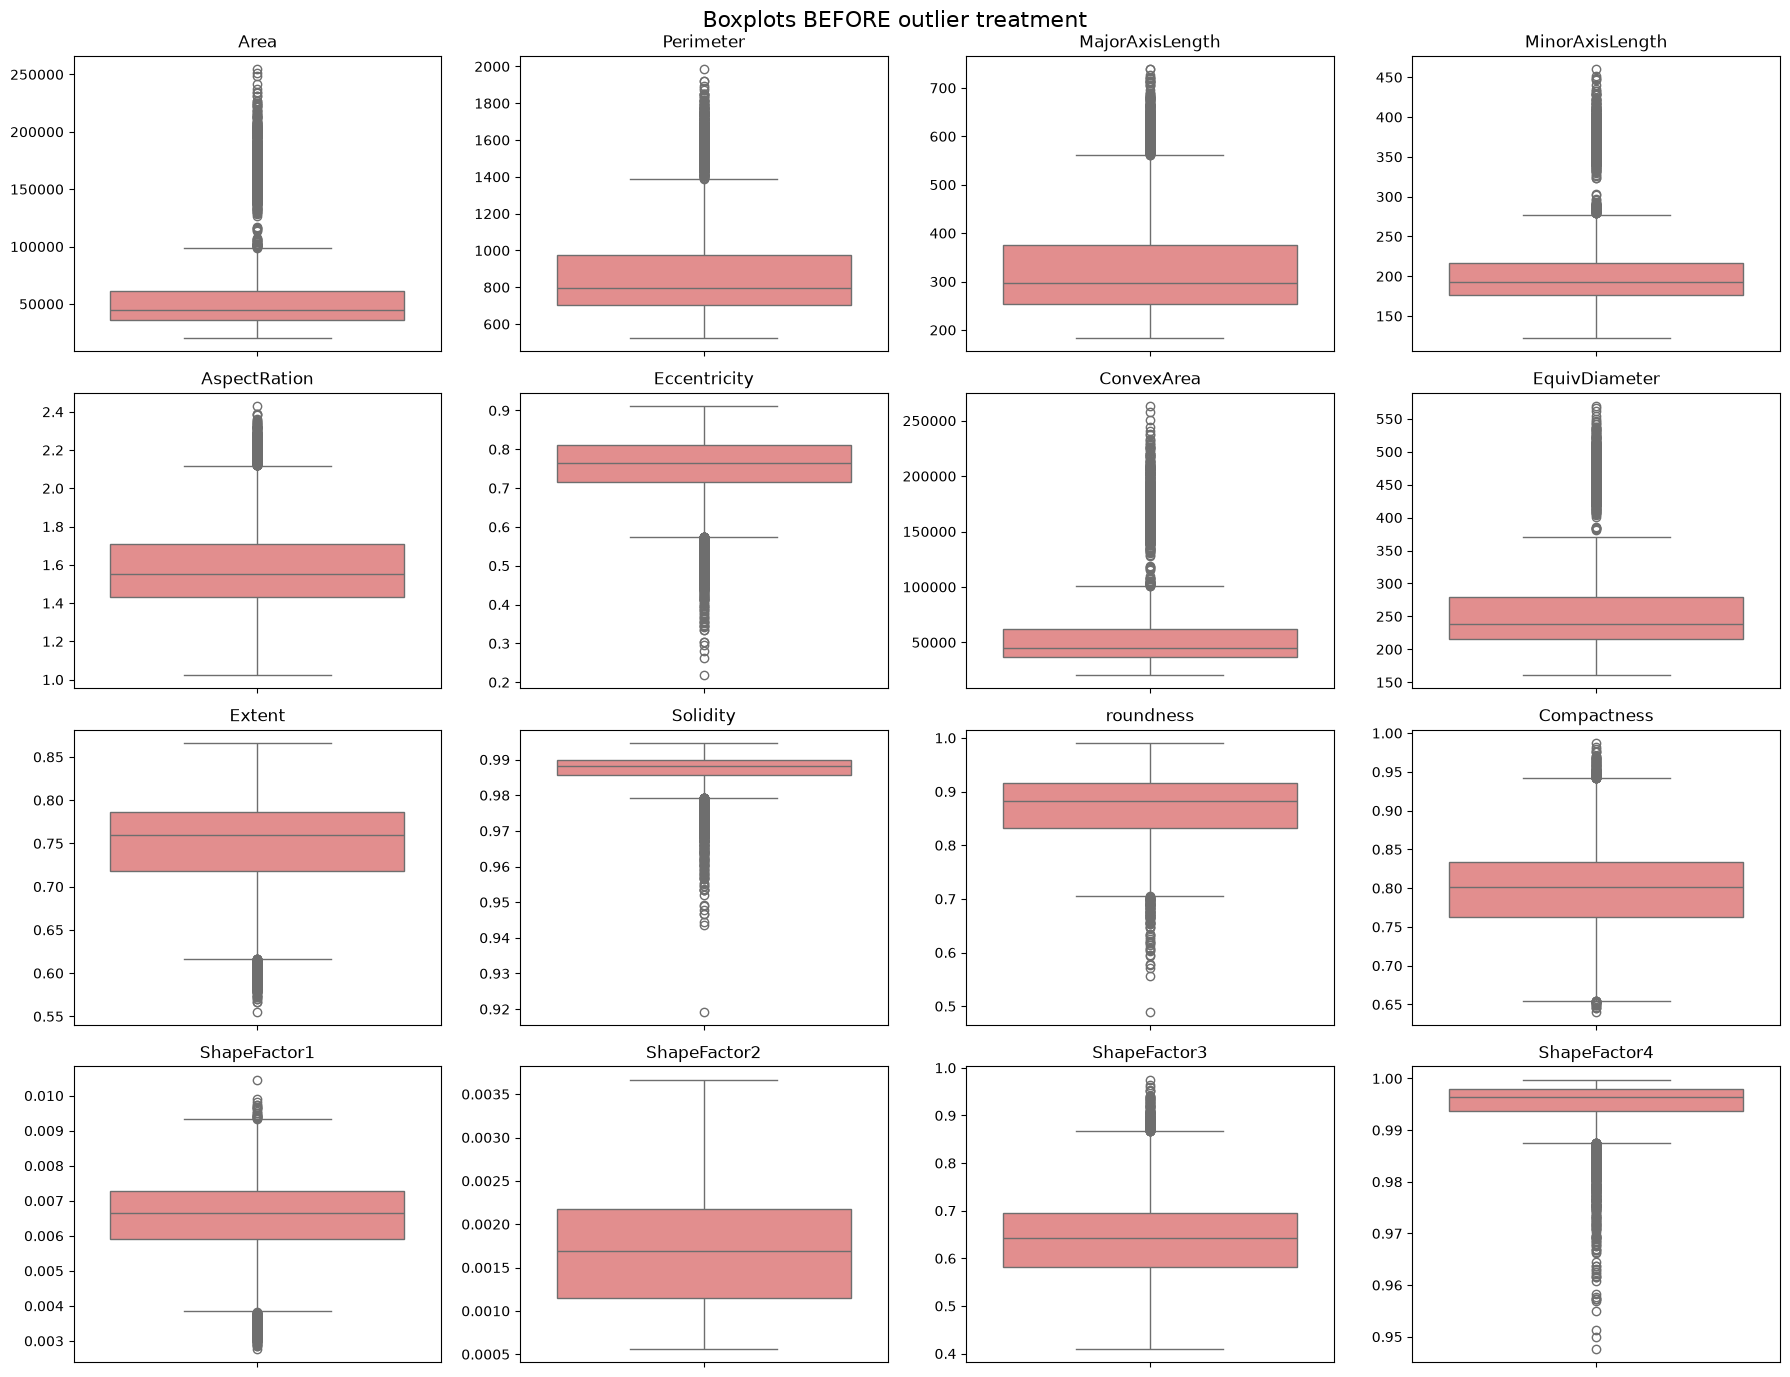

In [15]:
def boxplots(data, title):
    fig, axes = plt.subplots(4, 4, figsize=(18, 14))
    for ax, col in zip(axes.ravel(), features):
        sns.boxplot(y=data[col], ax=ax, color="lightcoral")
        ax.set_title(col)
        ax.set_ylabel("")
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()
 
boxplots(df, "Boxplots BEFORE outlier treatment")


**Outlier treatment:** these outliers are real beans (natural size/shape variation), and the final app uses the pipeline *raw → scaler → model*, so the outliers are **kept** (no capping). Set `CAP_OUTLIERS = True` only if you also cap new inputs in the app.

In [16]:
CAP_OUTLIERS = False

if CAP_OUTLIERS:
    for c in features:
        lo, hi = iqr_bounds(df[c])
        df[c] = df[c].clip(lower=lo, upper=hi)
    boxplots(df, "Boxplots AFTER capping (IQR winsorization)")
    print("Outliers capped.")
else:
    print("Outliers detected but kept (no capping).")

print(df[target].value_counts())

Outliers detected but kept (no capping).
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


## 4. Feature Engineering & Preprocessing

In [17]:
cat_cols = df[features].select_dtypes(include=["object", "category"]).columns.tolist()
print("Categorical independent variables:", cat_cols if cat_cols else "none -> no encoding needed")


Categorical independent variables: none -> no encoding needed


**Skewness:** only checked, not transformed, so the pipeline stays *raw → scaler → model*.

In [18]:
skew_before = df[features].skew()
print("Skewness of features:")
print(skew_before.round(2).sort_values(key=abs, ascending=False))

Skewness of features:
Area               2.95
ConvexArea         2.94
ShapeFactor4      -2.76
Solidity          -2.55
MinorAxisLength    2.24
EquivDiameter      1.95
Perimeter          1.63
MajorAxisLength    1.36
Eccentricity      -1.06
Extent            -0.90
roundness         -0.64
AspectRation       0.58
ShapeFactor1      -0.53
ShapeFactor2       0.30
ShapeFactor3       0.24
Compactness        0.04
dtype: float64


In [19]:
scaler = StandardScaler()
df[features] = scaler.fit_transform(df[features])
 
print("\nMean (~0) and std (~1) after scaling:")
print(pd.DataFrame({"mean": df[features].mean(), "std": df[features].std()}).round(3))



Mean (~0) and std (~1) after scaling:
                 mean  std
Area              0.0  1.0
Perimeter        -0.0  1.0
MajorAxisLength  -0.0  1.0
MinorAxisLength   0.0  1.0
AspectRation      0.0  1.0
Eccentricity     -0.0  1.0
ConvexArea        0.0  1.0
EquivDiameter    -0.0  1.0
Extent           -0.0  1.0
Solidity          0.0  1.0
roundness         0.0  1.0
Compactness       0.0  1.0
ShapeFactor1     -0.0  1.0
ShapeFactor2      0.0  1.0
ShapeFactor3      0.0  1.0
ShapeFactor4      0.0  1.0


In [20]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("\nTrain:", X_train.shape, " Test:", X_test.shape)
print("\nClass share (%) - full vs train vs test:")
print(pd.DataFrame({
    "full": y.value_counts(normalize=True).sort_index() * 100,
    "train": y_train.value_counts(normalize=True).sort_index() * 100,
    "test": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2))



Train: (10888, 16)  Test: (2723, 16)

Class share (%) - full vs train vs test:
           full  train   test
Class                        
BARBUNYA   9.71   9.71   9.73
BOMBAY     3.84   3.84   3.82
CALI      11.98  11.98  11.97
DERMASON  26.05  26.06  26.04
HOROZ     14.17  14.16  14.18
SEKER     14.89  14.89  14.91
SIRA      19.37  19.37  19.35


## 5. Model Building (with cross-validation)

In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(random_state=42),
    "Naive Bayes": GaussianNB(),
    # ---- Ensemble methods
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Bagging (Decision Tree)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=50, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}


In [22]:
models["Voting (LR+RF+SVM)"] = VotingClassifier(
    estimators=[("lr", LogisticRegression(max_iter=2000, random_state=42)),
                ("rf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
                ("svm", SVC(random_state=42))],
    voting="hard", n_jobs=-1)


In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
 
rows = []
for name, model in models.items():
    t0 = time.time()
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
 
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
 
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "CV Accuracy (mean)": cv_scores.mean(),
        "CV Std": cv_scores.std(),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test F1 (weighted)": f1_score(y_test, test_pred, average="weighted"),
        "Test F1 (macro)": f1_score(y_test, test_pred, average="macro"),
        "Train-Test Gap": accuracy_score(y_train, train_pred) - accuracy_score(y_test, test_pred),
        "Time (s)": time.time() - t0,
    })
    print(f"done: {name:25s} CV={cv_scores.mean():.4f}  Test={rows[-1]['Test Accuracy']:.4f}")
 
results = pd.DataFrame(rows).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
print("\n=== MODEL COMPARISON (sorted by test accuracy) ===")
print(results.round(4).to_string(index=False))
 
best = results.iloc[0]
print(f"\nBest model: {best['Model']}  (CV {best['CV Accuracy (mean)']:.4f}, Test {best['Test Accuracy']:.4f})")


done: Logistic Regression       CV=0.9244  Test=0.9210
done: Decision Tree             CV=0.8952  Test=0.8920
done: Random Forest             CV=0.9240  Test=0.9207
done: KNN                       CV=0.9231  Test=0.9170
done: SVM (RBF)                 CV=0.9305  Test=0.9221
done: Naive Bayes               CV=0.8970  Test=0.8979
done: Extra Trees               CV=0.9184  Test=0.9163
done: AdaBoost                  CV=0.8313  Test=0.8057
done: Bagging (Decision Tree)   CV=0.9235  Test=0.9188
done: Gradient Boosting         CV=0.9292  Test=0.9221
done: Voting (LR+RF+SVM)        CV=0.9298  Test=0.9221

=== MODEL COMPARISON (sorted by test accuracy) ===
                  Model  Train Accuracy  CV Accuracy (mean)  CV Std  Test Accuracy  Test F1 (weighted)  Test F1 (macro)  Train-Test Gap  Time (s)
              SVM (RBF)          0.9338              0.9305  0.0047         0.9221              0.9222           0.9343          0.0116    2.0775
      Gradient Boosting          0.9869            

In [24]:
results["CV vs Test diff"] = (results["CV Accuracy (mean)"] - results["Test Accuracy"]).abs()
print("\nLargest CV-vs-Test differences (possible instability):")
print(results.sort_values("CV vs Test diff", ascending=False)[["Model", "CV Accuracy (mean)", "Test Accuracy", "CV vs Test diff"]].head(3).round(4).to_string(index=False))



Largest CV-vs-Test differences (possible instability):
             Model  CV Accuracy (mean)  Test Accuracy  CV vs Test diff
          AdaBoost              0.8313         0.8057           0.0256
         SVM (RBF)              0.9305         0.9221           0.0083
Voting (LR+RF+SVM)              0.9298         0.9221           0.0077


## 6. Handling Class Imbalance

In [25]:
print("Train class counts:")
print(y_train.value_counts())
classes = sorted(y_train.unique())
minority = y_train.value_counts().nsmallest(3).index.tolist()     # 3 smallest classes
print("\nMinority classes focused on:", minority)


Train class counts:
Class
DERMASON    2837
SIRA        2109
SEKER       1621
HOROZ       1542
CALI        1304
BARBUNYA    1057
BOMBAY       418
Name: count, dtype: int64

Minority classes focused on: ['BOMBAY', 'BARBUNYA', 'CALI']


In [26]:
def get_model(name, balanced=False):
    cw = "balanced" if balanced else None
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=2000, class_weight=cw, random_state=42)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=100, class_weight=cw, random_state=42, n_jobs=-1)
    if name == "SVM (RBF)":
        return SVC(class_weight=cw, random_state=42)
 
samplers = {
    "Baseline (no handling)": None,
    "Class weighting": None,                      # handled inside the model
    "Random Oversampling": RandomOverSampler(random_state=42),
    "Random Undersampling": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
}


In [27]:
rows = []
for strategy, sampler in samplers.items():
    # Resample the TRAIN set only. The test set is never touched.
    if sampler is None:
        Xr, yr = X_train, y_train
    else:
        Xr, yr = sampler.fit_resample(X_train, y_train)
 
    for name in ["Logistic Regression", "Random Forest", "SVM (RBF)"]:
        model = get_model(name, balanced=(strategy == "Class weighting"))
        model.fit(Xr, yr)
        pred = model.predict(X_test)
 
        row = {
            "Strategy": strategy, "Model": name,
            "Train size": len(yr),
            "Accuracy": accuracy_score(y_test, pred),
            "Macro F1": f1_score(y_test, pred, average="macro"),
            "Weighted F1": f1_score(y_test, pred, average="weighted"),
        }
        f1_each = f1_score(y_test, pred, labels=classes, average=None)
        rec_each = recall_score(y_test, pred, labels=classes, average=None)
        for c, f, r in zip(classes, f1_each, rec_each):
            row[f"F1 {c}"] = f
            row[f"Recall {c}"] = r
        rows.append(row)
    print("done:", strategy)
 
res = pd.DataFrame(rows)


done: Baseline (no handling)
done: Class weighting
done: Random Oversampling
done: Random Undersampling
done: SMOTE


In [28]:
print("\n=== OVERALL (test set) ===")
print(res[["Model", "Strategy", "Train size", "Accuracy", "Macro F1", "Weighted F1"]]
      .sort_values(["Model", "Macro F1"], ascending=[True, False]).round(4).to_string(index=False))
 
print("\n=== MINORITY CLASSES: F1 score ===")
f1_cols = [f"F1 {c}" for c in minority]
print(res[["Model", "Strategy"] + f1_cols].sort_values(["Model", "Strategy"]).round(4).to_string(index=False))
 
print("\n=== MINORITY CLASSES: Recall (share of real beans of that class correctly found) ===")
rec_cols = [f"Recall {c}" for c in minority]
print(res[["Model", "Strategy"] + rec_cols].sort_values(["Model", "Strategy"]).round(4).to_string(index=False))
 
# Change versus baseline, per model
print("\n=== CHANGE vs BASELINE (percentage points) ===")
base = res[res["Strategy"] == "Baseline (no handling)"].set_index("Model")
chg = res[res["Strategy"] != "Baseline (no handling)"].copy()
for col in ["Accuracy", "Macro F1"] + f1_cols:
    chg[col] = (chg[col].values - base.loc[chg["Model"], col].values) * 100
print(chg[["Model", "Strategy", "Accuracy", "Macro F1"] + f1_cols]
      .sort_values(["Model", "Strategy"]).round(2).to_string(index=False))
 
best = res.sort_values("Macro F1", ascending=False).iloc[0]
print(f"\nBest macro F1: {best['Model']} + {best['Strategy']}  ({best['Macro F1']:.4f})")



=== OVERALL (test set) ===
              Model               Strategy  Train size  Accuracy  Macro F1  Weighted F1
Logistic Regression Baseline (no handling)       10888    0.9210    0.9333       0.9212
Logistic Regression    Random Oversampling       19859    0.9181    0.9313       0.9183
Logistic Regression        Class weighting       10888    0.9170    0.9305       0.9173
Logistic Regression                  SMOTE       19859    0.9159    0.9302       0.9161
Logistic Regression   Random Undersampling        2926    0.9115    0.9264       0.9117
      Random Forest    Random Oversampling       19859    0.9221    0.9347       0.9221
      Random Forest Baseline (no handling)       10888    0.9214    0.9339       0.9214
      Random Forest                  SMOTE       19859    0.9207    0.9325       0.9207
      Random Forest        Class weighting       10888    0.9181    0.9305       0.9180
      Random Forest   Random Undersampling        2926    0.9163    0.9297       0.9159
    

## 7. Model Evaluation & Overfitting Check

In [29]:
preds = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    preds[name] = p_te
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, p_tr),
        "Test Accuracy": accuracy_score(y_test, p_te),
        "Train F1 (macro)": f1_score(y_train, p_tr, average="macro"),
        "Test F1 (macro)": f1_score(y_test, p_te, average="macro"),
        "Test Precision (macro)": precision_score(y_test, p_te, average="macro"),
        "Test Recall (macro)": recall_score(y_test, p_te, average="macro"),
    })
 
res = pd.DataFrame(rows)


/Users/PRIYANKSHI/Documents/IIT Roorke/Beans_Multiclass_Classification/myenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


=== TRAIN vs TEST (sorted by test accuracy) ===
                  Model  Train Accuracy  Test Accuracy  Train F1 (macro)  Test F1 (macro)  Test Precision (macro)  Test Recall (macro)  Accuracy Gap  F1 Gap Overfitting (Y/N)
              SVM (RBF)          0.9338         0.9221            0.9449           0.9343                  0.9359               0.9330        0.0116  0.0106                 N
      Gradient Boosting          0.9869         0.9221            0.9903           0.9344                  0.9368               0.9321        0.0647  0.0560                 Y
     Voting (LR+RF+SVM)          0.9424         0.9221            0.9520           0.9338                  0.9353               0.9324        0.0203  0.0182                 N
    Logistic Regression          0.9261         0.9210            0.9377           0.9333                  0.9351               0.9319        0.0050  0.0044                 N
          Random Forest          1.0000         0.9207            1.0000     

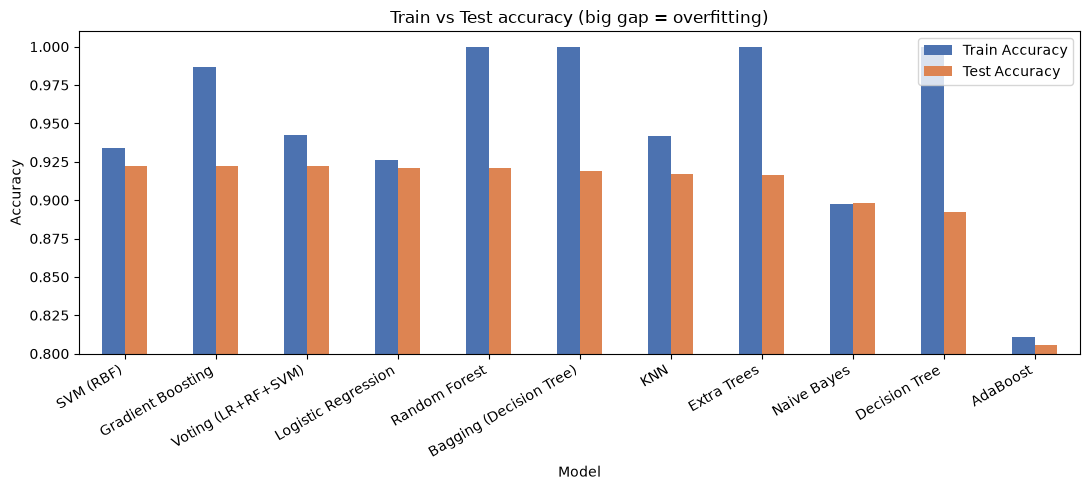

In [30]:
GAP_LIMIT = 0.03
res["Accuracy Gap"] = res["Train Accuracy"] - res["Test Accuracy"]
res["F1 Gap"] = res["Train F1 (macro)"] - res["Test F1 (macro)"]
res["Overfitting (Y/N)"] = np.where(res["Accuracy Gap"] > GAP_LIMIT, "Y", "N")
res = res.sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
 
print("=== TRAIN vs TEST (sorted by test accuracy) ===")
print(res.round(4).to_string(index=False))
 
# Bar chart: train vs test accuracy
ax = res.set_index("Model")[["Train Accuracy", "Test Accuracy"]].plot(
    kind="bar", figsize=(11, 5), color=["#4C72B0", "#DD8452"])
ax.set_ylim(0.8, 1.01)
ax.set_title("Train vs Test accuracy (big gap = overfitting)")
ax.set_ylabel("Accuracy")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [31]:
labels = sorted(y_train.unique())
best_name = res.iloc[0]["Model"]
print(f"\n=== CLASSIFICATION REPORT: {best_name} (precision / recall / F1 per class) ===")
print(classification_report(y_test, preds[best_name], digits=3))
 
# Per-class F1 for every model side by side
f1_table = pd.DataFrame({n: f1_score(y_test, p, labels=labels, average=None)
                         for n, p in preds.items()}, index=labels)
print("Per-class F1 on the test set, all models:")
print(f1_table.round(3))



=== CLASSIFICATION REPORT: SVM (RBF) (precision / recall / F1 per class) ===
              precision    recall  f1-score   support

    BARBUNYA      0.948     0.891     0.918       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.934     0.948     0.941       326
    DERMASON      0.915     0.913     0.914       709
       HOROZ      0.959     0.959     0.959       386
       SEKER      0.937     0.948     0.942       406
        SIRA      0.860     0.873     0.866       527

    accuracy                          0.922      2723
   macro avg      0.936     0.933     0.934      2723
weighted avg      0.922     0.922     0.922      2723

Per-class F1 on the test set, all models:
          Logistic Regression  Decision Tree  Random Forest    KNN  SVM (RBF)  \
BARBUNYA                0.920          0.894          0.915  0.912      0.918   
BOMBAY                  1.000          1.000          1.000  1.000      1.000   
CALI                    0.936          0

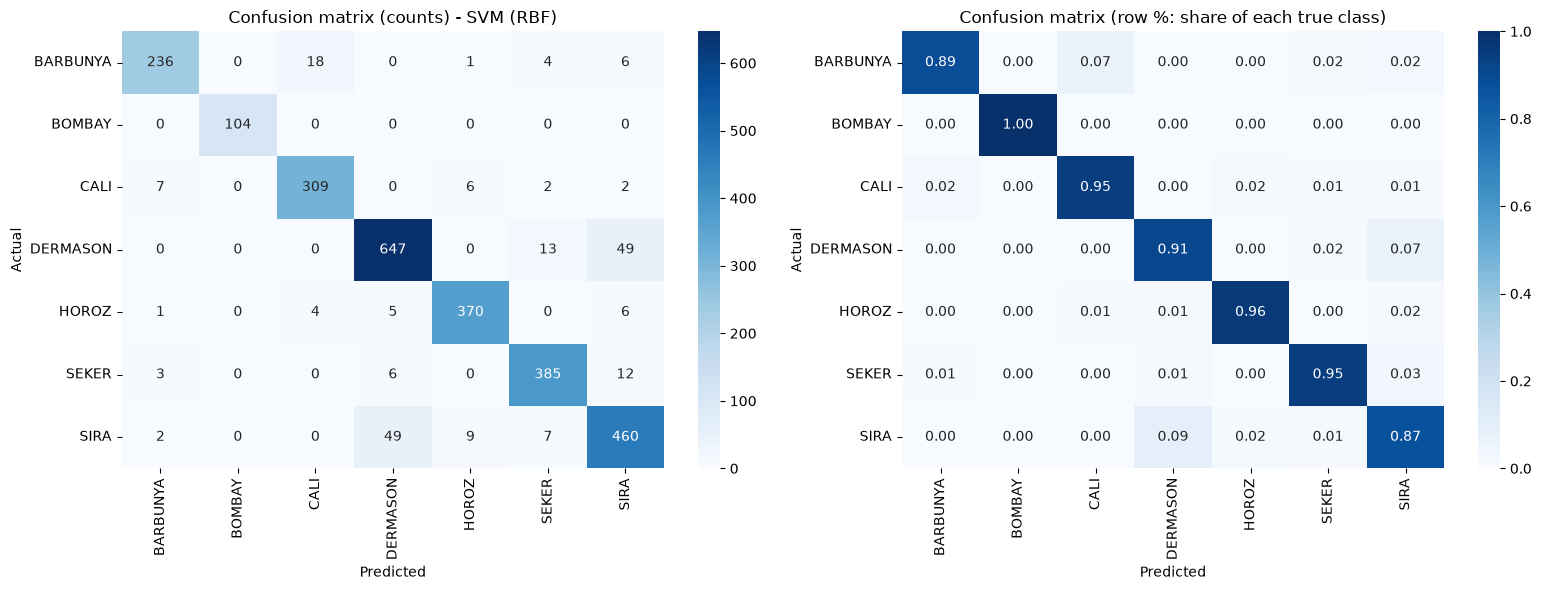

Most frequent confusions (actual -> predicted : count):
  DERMASON -> SIRA : 49
  SIRA -> DERMASON : 49
  BARBUNYA -> CALI : 18
  DERMASON -> SEKER : 13
  SEKER -> SIRA : 12


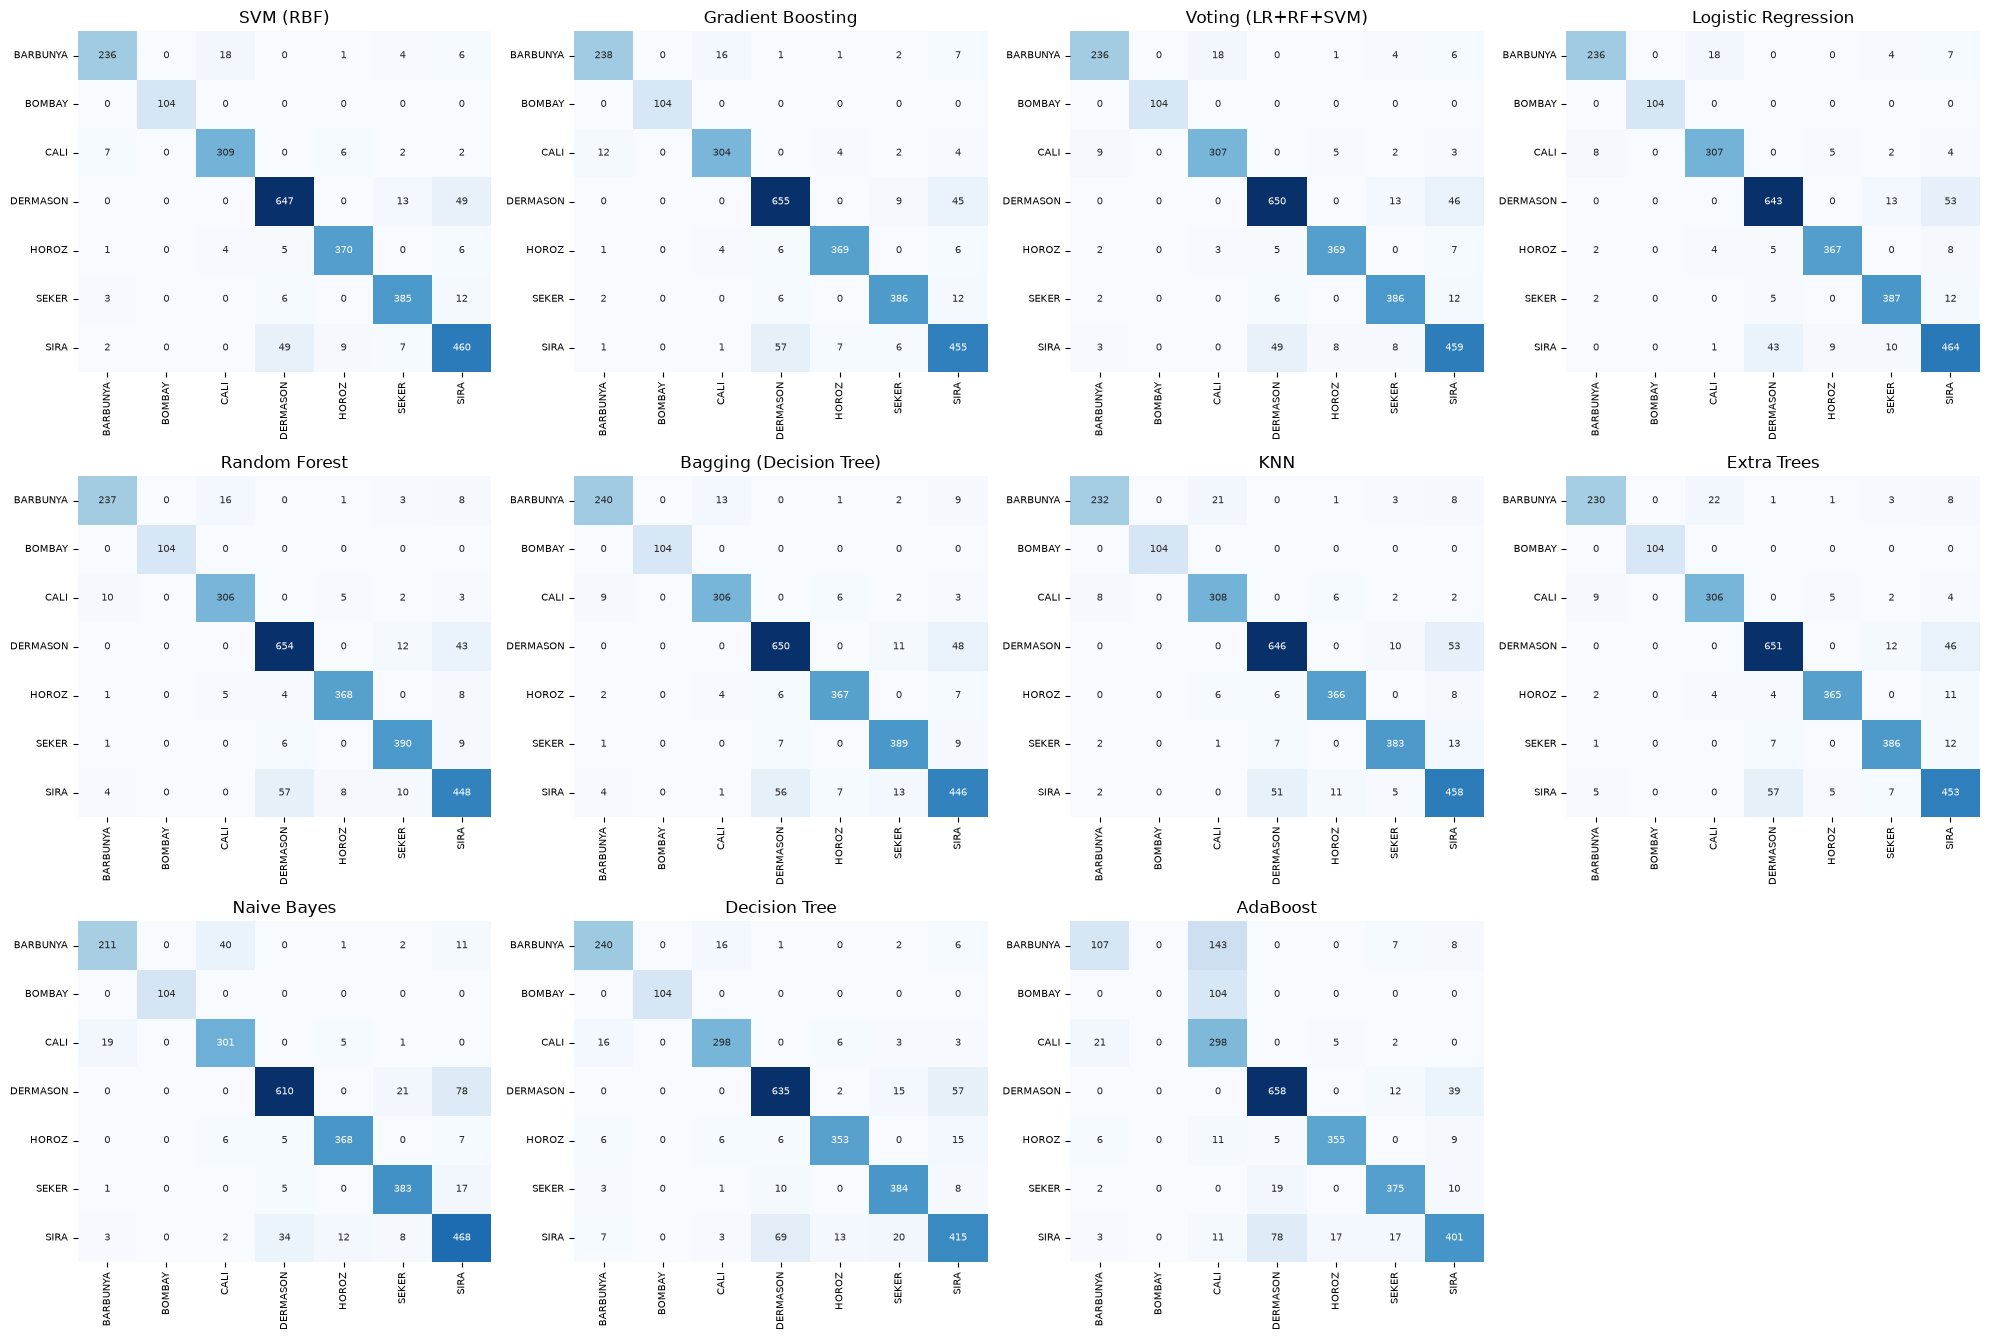


=== SUMMARY ===
Best model on test set: SVM (RBF) (accuracy 0.9221, macro F1 0.9343)
Overfitting (train-test accuracy gap > 3 pts): Gradient Boosting, Random Forest, Bagging (Decision Tree), Extra Trees, Decision Tree
Not overfitting: SVM (RBF), Voting (LR+RF+SVM), Logistic Regression, KNN, Naive Bayes, AdaBoost


In [32]:
cm = confusion_matrix(y_test, preds[best_name], labels=labels)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title(f"Confusion matrix (counts) - {best_name}")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title("Confusion matrix (row %: share of each true class)")
for a in axes:
    a.set_xlabel("Predicted")
    a.set_ylabel("Actual")
plt.tight_layout()
plt.show()
 
# Most common mistakes of the best model
errors = [(labels[i], labels[j], cm[i, j]) for i in range(len(labels)) for j in range(len(labels)) if i != j and cm[i, j] > 0]
errors = sorted(errors, key=lambda t: -t[2])[:5]
print("Most frequent confusions (actual -> predicted : count):")
for a, b, n in errors:
    print(f"  {a} -> {b} : {n}")
 
# ---------------------------------------------------- confusion matrices for all models
n = len(models)
cols = 4
rows_n = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(5 * cols, 4.5 * rows_n))
for ax, name in zip(axes.ravel(), res["Model"]):
    c = confusion_matrix(y_test, preds[name], labels=labels)
    sns.heatmap(c, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels, annot_kws={"size": 7})
    ax.set_title(name)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()
 
# ---------------------------------------------------- summary
print("\n=== SUMMARY ===")
print(f"Best model on test set: {best_name} (accuracy {res.iloc[0]['Test Accuracy']:.4f}, macro F1 {res.iloc[0]['Test F1 (macro)']:.4f})")
over = res.loc[res["Overfitting (Y/N)"] == "Y", "Model"].tolist()
print("Overfitting (train-test accuracy gap > 3 pts):", ", ".join(over) if over else "none")
print("Not overfitting:", ", ".join(res.loc[res["Overfitting (Y/N)"] == "N", "Model"]))


## 8 & 9. Hyperparameter Tuning and Model Comparison Table

In [33]:
SCORING = "f1_macro"      # tune on macro F1 so every class counts equally
GAP_LIMIT = 0.03   
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "SVM": SVC(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
}
 
def evaluate(model):
    """Return train acc, test acc, test macro F1 for a fitted model."""
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    return (accuracy_score(y_train, p_tr), accuracy_score(y_test, p_te),
            f1_score(y_test, p_te, average="macro"))
 
baseline = {}
for name, m in baseline_models.items():
    m.fit(X_train, y_train)
    baseline[name] = evaluate(m)
 
# ====================================================================  STEP 8: TUNING
# (name, search object). GridSearchCV tries every combination; RandomizedSearchCV samples n_iter of them.
searches = {
    "Logistic Regression": GridSearchCV(
        LogisticRegression(max_iter=3000, random_state=42),
        {"C": [0.01, 0.1, 1, 10, 100], "solver": ["lbfgs", "newton-cg"]},
        cv=cv, scoring=SCORING, n_jobs=-1),
    "KNN": GridSearchCV(
        KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 7, 9, 11, 15, 21], "weights": ["uniform", "distance"], "p": [1, 2]},
        cv=cv, scoring=SCORING, n_jobs=-1),
    "SVM": GridSearchCV(
        SVC(random_state=42),
        {"C": [1, 5, 10, 50, 100], "gamma": ["scale", 0.01, 0.03, 0.1], "kernel": ["rbf"]},
        cv=cv, scoring=SCORING, n_jobs=-1),
    "Decision Tree": GridSearchCV(
        DecisionTreeClassifier(random_state=42),
        {"max_depth": [3, 5, 7, 10, 15, None], "min_samples_split": [2, 10, 30], "min_samples_leaf": [1, 5, 15],
         "criterion": ["gini", "entropy"]},
        cv=cv, scoring=SCORING, n_jobs=-1),
    "Random Forest": RandomizedSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=1),
        {"n_estimators": randint(100, 300), "max_depth": [8, 12, 16, 20, None],
         "min_samples_split": randint(2, 20), "min_samples_leaf": randint(1, 10),
         "max_features": ["sqrt", "log2", 0.5]},
        n_iter=15, cv=cv, scoring=SCORING, n_jobs=-1, random_state=42),
}
 
tuned = {}
best_params_rows = []
for name, search in searches.items():
    t0 = time.time()
    search.fit(X_train, y_train)
    tuned[name] = (search.best_estimator_, *evaluate(search.best_estimator_))
    b_tr, b_te, b_f1 = baseline[name]
    t_tr, t_te, t_f1 = tuned[name][1:]
    best_params_rows.append({
        "Model": name,
        "Search": type(search).__name__,
        "Best Params": search.best_params_,
        "Best CV macro-F1": search.best_score_,
        "Test Acc (before)": b_te, "Test Acc (after)": t_te,
        "Test F1 (before)": b_f1, "Test F1 (after)": t_f1,
        "Acc Change (pts)": (t_te - b_te) * 100,
        "Gap (before)": b_tr - b_te, "Gap (after)": t_tr - t_te,
    })
    print(f"tuned {name:20s} in {time.time() - t0:5.0f}s   best CV macro-F1 = {search.best_score_:.4f}")
 
tuning = pd.DataFrame(best_params_rows)
print("\n=== STEP 8: BEST PARAMETERS ===")
for _, r in tuning.iterrows():
    print(f"{r['Model']:20s} [{r['Search']}]  {r['Best Params']}")
 
print("\n=== STEP 8: PERFORMANCE BEFORE vs AFTER TUNING ===")
print(tuning.drop(columns=["Best Params", "Search"]).round(4).to_string(index=False))
 
# ====================================================================  STEP 9: COMPARISON TABLE
rows = []
for name, (tr, te, f1) in baseline.items():
    rows.append({"Model": name, "Version": "Default", "Train Accuracy": tr, "Test Accuracy": te, "F1 Score": f1})
for name, (_, tr, te, f1) in tuned.items():
    rows.append({"Model": name, "Version": "Tuned", "Train Accuracy": tr, "Test Accuracy": te, "F1 Score": f1})
 
comp = pd.DataFrame(rows)
comp["Overfitting (Y/N)"] = np.where(comp["Train Accuracy"] - comp["Test Accuracy"] > GAP_LIMIT, "Y", "N")
comp = comp.sort_values(["Model", "Version"], ascending=[True, False]).reset_index(drop=True)
 
print("\n=== STEP 9: MODEL COMPARISON TABLE (F1 = macro F1 on test set) ===")
print(comp.round(4).to_string(index=False))
 
# Best model = highest test macro F1 among models that are NOT overfitting
ok = comp[comp["Overfitting (Y/N)"] == "N"]
best = ok.sort_values(["F1 Score", "Test Accuracy"], ascending=False).iloc[0]
print("\n=== BEST MODEL ===")
print(f"{best['Model']} ({best['Version']}): train acc {best['Train Accuracy']:.4f}, test acc {best['Test Accuracy']:.4f}, "
      f"F1 {best['F1 Score']:.4f}, overfitting: {best['Overfitting (Y/N)']}")
 
best_model = tuned[best["Model"]][0] if best["Version"] == "Tuned" else baseline_models[best["Model"]]


tuned Logistic Regression  in     1s   best CV macro-F1 = 0.9374
tuned KNN                  in     4s   best CV macro-F1 = 0.9384
tuned SVM                  in    11s   best CV macro-F1 = 0.9445
tuned Decision Tree        in    12s   best CV macro-F1 = 0.9223
tuned Random Forest        in    62s   best CV macro-F1 = 0.9366

=== STEP 8: BEST PARAMETERS ===
Logistic Regression  [GridSearchCV]  {'C': 100, 'solver': 'newton-cg'}
KNN                  [GridSearchCV]  {'n_neighbors': 9, 'p': 2, 'weights': 'distance'}
SVM                  [GridSearchCV]  {'C': 5, 'gamma': 0.1, 'kernel': 'rbf'}
Decision Tree        [GridSearchCV]  {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 15, 'min_samples_split': 2}
Random Forest        [RandomizedSearchCV]  {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 13, 'n_estimators': 157}

=== STEP 8: PERFORMANCE BEFORE vs AFTER TUNING ===
              Model  Best CV macro-F1  Test Acc (before)  Test Acc (after)  T

## 10. Save the model and scaler for the Streamlit app

In [34]:
import joblib

joblib.dump(best_model, "bean_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Saved: bean_model.pkl, scaler.pkl")

Saved: bean_model.pkl, scaler.pkl


Sanity check: real (raw) measurements -> scaler -> model, exactly what `app.py` does. Accuracy should be ~0.92 or higher.

In [35]:
raw = pd.read_csv("Beans_Dataset.csv").sample(1000, random_state=1)
X_new = pd.DataFrame(scaler.transform(raw[features]), columns=features)
pred = best_model.predict(X_new)
print("Accuracy through the app pipeline:", (pred == raw[target].values).mean())
print(pd.Series(pred).value_counts())

Accuracy through the app pipeline: 0.949
DERMASON    277
SIRA        206
SEKER       155
HOROZ       123
CALI        113
BARBUNYA     90
BOMBAY       36
Name: count, dtype: int64
